# Explainable Student Performance Prediction
## Final Year Project — TY B.Sc. Data Science

**Authors**: Data Science Student Project Team  
**Primary Model**: Random Forest Classifier  
**Baseline Model**: Logistic Regression  
**Explainable AI**: SHAP (SHapley Additive exPlanations)  
**Target**: Performance Category (`Low`, `Medium`, `High`)

---

### 🎯 Project Objectives
1. Clean, validate, and preprocess academic records from raw CSV.
2. Conduct Exploratory Data Analysis (EDA) to discover key academic correlations.
3. Enforce **strict anti-data-leakage protocols** (quarantining `Final_Score` and `Performance_Category`).
4. Train and benchmark multiple Machine Learning models (Random Forest, Logistic Regression, XGBoost).
5. Calculate multi-class evaluation metrics (Accuracy, Precision, Recall, F1, Confusion Matrix).
6. Implement SHAP for global feature importance and individual student explanations.

## 1. Environment Setup and Library Imports

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import shap

# Add project root to sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Set visual styles
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')
print("Libraries loaded successfully!")

Libraries loaded successfully!


## 2. Dataset Loading & Inspection
We begin by inspecting the raw dataset (`unclean_student_data.csv`), observing data anomalies such as duplicates, missing values, and formatting issues.

In [2]:
raw_path = os.path.join(project_root, 'data', 'raw', 'unclean_student_data.csv')
df_raw = pd.read_csv(raw_path)
print(f"Raw dataset shape: {df_raw.shape}")
print("\nMissing values count:")
print(df_raw.isnull().sum())
print("\nDuplicate rows:", df_raw.duplicated(subset=['Student_ID']).sum())


Raw dataset shape: (1200, 10)

Missing values count:
Student_ID                    0
Attendance_Percentage        42
Study_Hours                  42
Previous_Marks               42
Assignment_Score             42
Internal_Assessment_Marks    42
Completed_Assignments        42
Academic_Participation       42
Final_Score                   0
Performance_Category          0
dtype: int64

Duplicate rows: 200


## 3. Automated Data Cleaning Pipeline
We invoke the modular cleaning pipeline (`src.data_cleaning`) to remove duplicate records, impute missing values, filter out-of-range rows, and standardize categorical values.

In [3]:
from src.data_cleaning import clean_raw_data

df_clean, audit_report = clean_raw_data(df_raw)
print(f"Cleaned dataset shape: {df_clean.shape}")
print(f"Duplicates removed: {audit_report['duplicates_removed']}")
print(f"Casing inconsistencies fixed: {audit_report['casing_inconsistencies_fixed']}")


Cleaned dataset shape: (960, 10)
Duplicates removed: 200
Casing inconsistencies fixed: 500


## 4. Exploratory Data Analysis (EDA)
Examining patterns between student habits, attendance, and their overall performance.

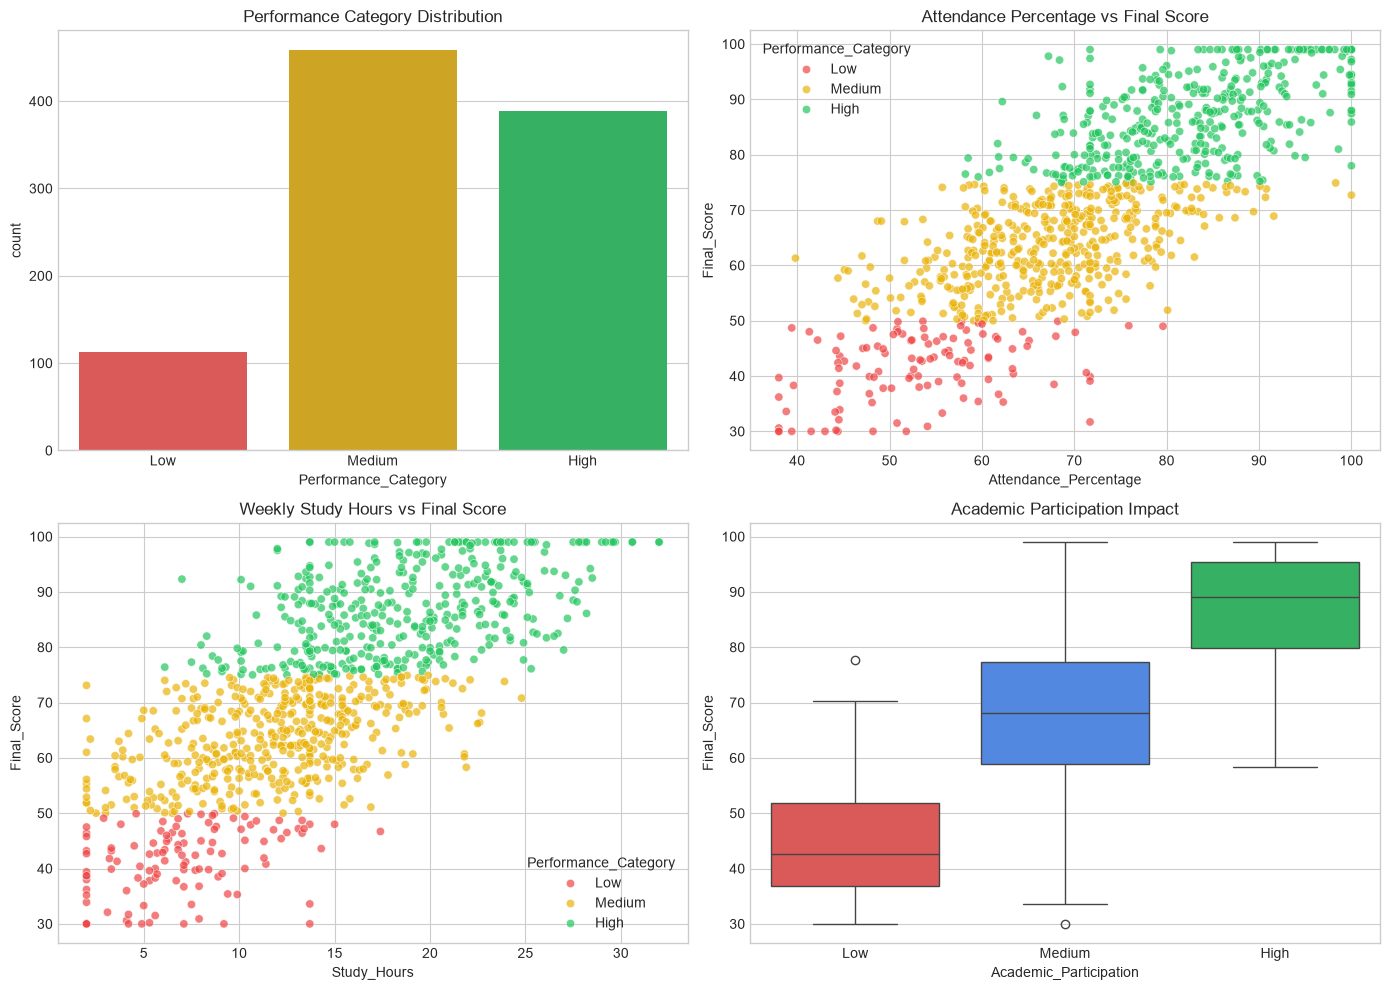

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Performance Category Distribution
sns.countplot(data=df_clean, x='Performance_Category', order=['Low', 'Medium', 'High'], ax=axes[0, 0], palette=['#ef4444', '#eab308', '#22c55e'])
axes[0, 0].set_title('Performance Category Distribution')

# 2. Attendance vs Final Score
sns.scatterplot(data=df_clean, x='Attendance_Percentage', y='Final_Score', hue='Performance_Category', hue_order=['Low', 'Medium', 'High'], palette=['#ef4444', '#eab308', '#22c55e'], alpha=0.7, ax=axes[0, 1])
axes[0, 1].set_title('Attendance Percentage vs Final Score')

# 3. Study Hours vs Final Score
sns.scatterplot(data=df_clean, x='Study_Hours', y='Final_Score', hue='Performance_Category', hue_order=['Low', 'Medium', 'High'], palette=['#ef4444', '#eab308', '#22c55e'], alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title('Weekly Study Hours vs Final Score')

# 4. Academic Participation vs Final Score
sns.boxplot(data=df_clean, x='Academic_Participation', y='Final_Score', order=['Low', 'Medium', 'High'], ax=axes[1, 1], palette=['#ef4444', '#3b82f6', '#22c55e'])
axes[1, 1].set_title('Academic Participation Impact')

plt.tight_layout()
plt.show()

### Correlation Heatmap
Visualizing correlations among continuous academic features.

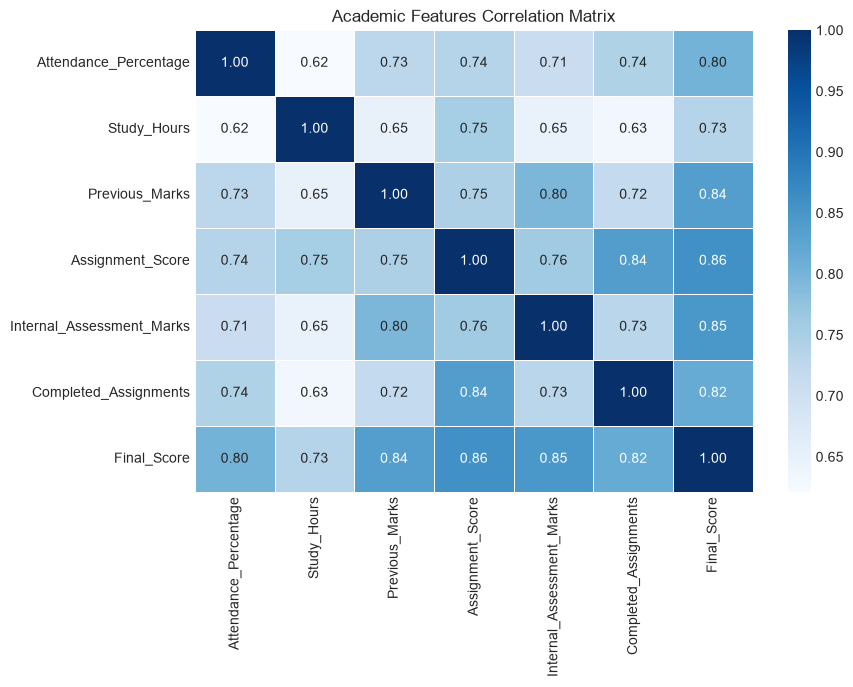

In [5]:
plt.figure(figsize=(9, 6))
num_cols = ['Attendance_Percentage', 'Study_Hours', 'Previous_Marks', 'Assignment_Score', 'Internal_Assessment_Marks', 'Completed_Assignments', 'Final_Score']
sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Academic Features Correlation Matrix')
plt.show()

## 5. Feature Engineering & Strict Anti-Data-Leakage Quarantine
**Crucial Rule**: `Final_Score` and `Performance_Category` are ground truth targets and are **strictly excluded** from feature matrix $X$.

In [6]:
from src.preprocessing import prepare_dataset, verify_no_data_leakage

prepared = prepare_dataset(df_clean, test_size=0.2, random_state=42)

X_train = prepared['X_train']
X_test = prepared['X_test']
X_train_scaled = prepared['X_train_scaled']
X_test_scaled = prepared['X_test_scaled']
y_train = prepared['y_train']
y_test = prepared['y_test']
feature_names = prepared['feature_names']

print(f"Training instances: {X_train.shape[0]}")
print(f"Testing instances: {X_test.shape[0]}")
print(f"Features ({len(feature_names)}): {feature_names}")

Training instances: 768
Testing instances: 192
Features (7): ['Attendance_Percentage', 'Study_Hours', 'Previous_Marks', 'Assignment_Score', 'Internal_Assessment_Marks', 'Completed_Assignments', 'Academic_Participation']


## 6. Model Training & Evaluation
We train and benchmark:
1. **Random Forest Classifier** (Primary)
2. **Logistic Regression** (Baseline)

In [7]:
# 1. Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_split=4, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

# 2. Logistic Regression (uses scaled data)
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)

models_eval = {
    "Random Forest": (y_test, rf_preds),
    "Logistic Regression": (y_test, lr_preds)
}

results = []
for m_name, (y_true, y_pred) in models_eval.items():
    results.append({
        "Model": m_name,
        "Accuracy": f"{accuracy_score(y_true, y_pred)*100:.2f}%",
        "Macro Precision": f"{precision_score(y_true, y_pred, average='macro'):.3f}",
        "Macro Recall": f"{recall_score(y_true, y_pred, average='macro'):.3f}",
        "Macro F1": f"{f1_score(y_true, y_pred, average='macro'):.3f}"
    })

df_res = pd.DataFrame(results)


### Confusion Matrices

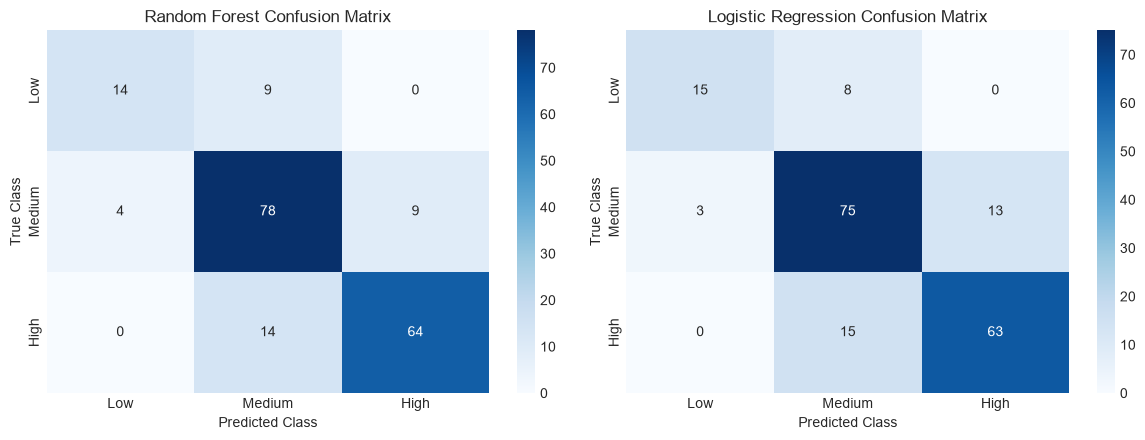

In [8]:
labels = ['Low', 'Medium', 'High']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(y_test, rf_preds), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')

sns.heatmap(confusion_matrix(y_test, lr_preds), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')

plt.tight_layout()
plt.show()

## 7. Explainable AI with SHAP (SHapley Additive exPlanations)
SHAP applies cooperative game theory to quantify how much each student feature moved the prediction from the base value to the model's output.

Global SHAP feature importance summary plot (High Performance Class):


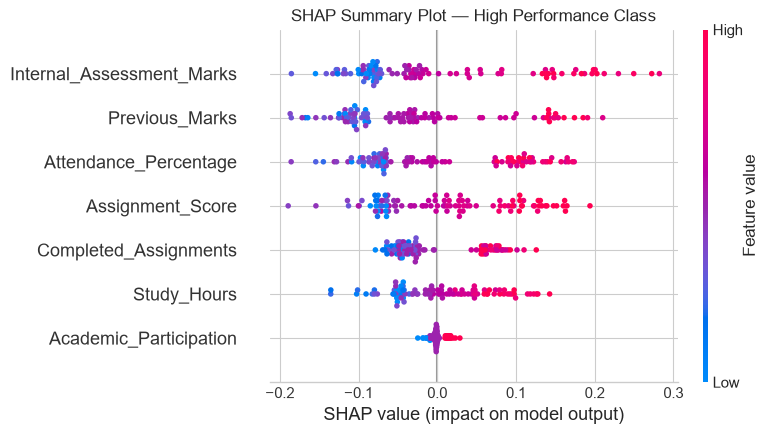

In [9]:
explainer = shap.TreeExplainer(rf)
sample_X = X_test.iloc[:100]
shap_vals = explainer.shap_values(sample_X)

print("Global SHAP feature importance summary plot (High Performance Class):")
shap.summary_plot(shap_vals[2] if isinstance(shap_vals, list) else shap_vals[:, :, 2], sample_X, feature_names=feature_names, show=False)
plt.title('SHAP Summary Plot — High Performance Class', fontsize=12)
plt.show()

### Individual Student Explanation
We inspect a single student and decompose the driving positive and negative factors.

In [10]:
from src.explainability import ShapExplainerService

xai_service = ShapExplainerService()
student_example = X_test.iloc[0].to_dict()
predicted_cat_idx = rf.predict(X_test.iloc[[0]])[0]

explanation = xai_service.explain_individual_student(student_example, predicted_cat_idx)

print(f"Predicted Category: {explanation['predicted_category']}")
print("\n--- Positive Contributing Factors ---")
for s in explanation['readable_positive']:
    print(s)
print("\n--- Negative Constraints ---")
for s in explanation['readable_negative']:
    print(s)

Predicted Category: High

--- Positive Contributing Factors ---
[+] Internal Assessment Marks (44.9 / 50) contributed positively (+0.25) toward High performance
[+] Assignment Performance (100.0%) contributed positively (+0.16) toward High performance
[+] Weekly Study Hours (18.6 hrs/week) contributed positively (+0.05) toward High performance

--- Negative Constraints ---
[-] Previous Semester Marks (62.8%) pulled prediction down (-0.10)
[-] Assignments Completed (Count) (7.0) pulled prediction down (-0.03)


## 8. Conclusion & Summary
- Successfully cleaned raw academic data and eliminated data leakage.
- Benchmarked primary Random Forest against baseline Logistic Regression.
- Deployed SHAP Explainability to illuminate the black box into transparent, actionable guidance for educators and students.